# TP1 – Ciência de Dados 1 (EST – 2026/02)

**Aluno:** Gabriel Cortez de São Paulo Rozeno · **Matrícula:** 2215080052  
**Professor:** Márcio Palheta Piedade, D.Sc. · Sistemas de Informação

**Análise exploratória de duas bases reais com Pandas e Matplotlib**

- **Base 1:** Netflix Movies and TV Shows (Kaggle – `shivamb/netflix-shows`)
- **Base 2:** Students Performance in Exams (Kaggle – `spscientist/students-performance-in-exams`)

Os arquivos estão em `data/` (para baixar de novo: `python baixar_dados.py`).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)
pd.set_option('display.float_format', '{:.2f}'.format)

# Visual dos gráficos: sem bordas de cima/direita, título em destaque, grade discreta
plt.rcParams.update({
    'figure.figsize': (10, 5),
    'figure.dpi': 110,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.axisbelow': True,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.titlelocation': 'left',
    'axes.titlepad': 12,
    'axes.labelsize': 11,
    'legend.frameon': False,
})

# Visual das tabelas: cabeçalho escuro, linhas zebradas e números alinhados
display(HTML("""<style>
table.dataframe { border-collapse: collapse; border: none; font-size: 13px; margin: 6px 0; }
table.dataframe thead th { background: #2b3a55; color: #fff; padding: 7px 12px; text-align: center; border: none; }
table.dataframe tbody th { background: rgba(43, 58, 85, 0.10); padding: 5px 12px; text-align: left; font-weight: 600; border: none; }
table.dataframe td { padding: 5px 12px; text-align: right; border: none; border-bottom: 1px solid rgba(127, 127, 127, 0.20); }
table.dataframe tbody tr:nth-child(even) td { background: rgba(127, 127, 127, 0.06); }
table.dataframe tbody tr:hover td { background: rgba(31, 119, 180, 0.12); }
</style>"""))


def tabela(dados, barras=(), casas=2):
    """Mostra uma Series/DataFrame como tabela, com barras proporcionais nas colunas de `barras`."""
    if isinstance(dados, pd.Series):
        dados = dados.to_frame()
    estilo = dados.style.format(precision=casas).set_table_attributes('class="dataframe"')
    if barras:
        estilo = estilo.bar(subset=list(barras), color='#9ecae1', vmin=0)
    return estilo

---
# 1. Netflix – conhecendo e preparando os dados

In [2]:
netflix = pd.read_csv('data/netflix_titles.csv')
print('Linhas:', netflix.shape[0], '| Colunas:', netflix.shape[1])

Linhas: 8807 | Colunas: 12


### 5 primeiras e 5 últimas linhas

In [3]:
netflix.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [4]:
netflix.tail()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."
8806,s8807,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...",India,"March 2, 2019",2015,TV-14,111 min,"Dramas, International Movies, Music & Musicals",A scrappy but poor boy worms his way into a ty...


### Seleção com `loc` e `iloc`

`iloc` seleciona por **posição** (0, 1, 2… e negativos contam do fim), e `loc` seleciona por **rótulo** do índice
ou por **condição** (máscara booleana), já escolhendo as colunas pelo nome. Ao longo do notebook, os filtros usam `loc`.

In [5]:
# iloc: as 5 últimas linhas por posição (equivale a tail()) e só as 3 primeiras colunas
display(netflix.iloc[-5:, :3])

# loc: filtro por condição + colunas pelo nome
netflix.loc[(netflix['type'] == 'Movie') & (netflix['release_year'] < 1945), ['title', 'release_year', 'duration']]

,show_id,type,title
8802,s8803,Movie,Zodiac
8803,s8804,TV Show,Zombie Dumb
8804,s8805,Movie,Zombieland
8805,s8806,Movie,Zoom
8806,s8807,Movie,Zubaan


,title,release_year,duration
7790,Prelude to War,1942,52 min
8205,The Battle of Midway,1942,18 min
8419,The Memphis Belle: A Story of a\nFlying Fortress,1944,40 min
8436,The Negro Soldier,1944,40 min
8640,Tunisian Victory,1944,76 min
8660,Undercover: How to Operate Behind Enemy Lines,1943,61 min
8739,Why We Fight: The Battle of Russia,1943,82 min
8763,WWII: Report from the Aleutians,1943,45 min


### Colunas e tipos

In [6]:
print(list(netflix.columns))
netflix.dtypes.rename('tipo').to_frame()

['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']


,tipo
show_id,str
type,str
title,str
director,str
cast,str
country,str
date_added,str
release_year,int64
rating,str
duration,str


### Valores ausentes e duplicados

In [7]:
ausentes = netflix.isna().sum()
tabela(pd.DataFrame({'ausentes': ausentes, '%': (ausentes / len(netflix) * 100).round(1)})
       .sort_values('ausentes', ascending=False), barras=['%'], casas=1)

,ausentes,%
director,2634,29.9
country,831,9.4
cast,825,9.4
date_added,10,0.1
rating,4,0.0
duration,3,0.0
show_id,0,0.0
type,0,0.0
title,0,0.0
release_year,0,0.0


In [8]:
pd.Series({
    'Linhas duplicadas': netflix.duplicated().sum(),
    'show_id duplicados': netflix['show_id'].duplicated().sum(),
    'Títulos repetidos (mesmo título, linhas diferentes)': netflix['title'].duplicated().sum(),
}).to_frame('quantidade')

,quantidade
Linhas duplicadas,0
show_id duplicados,0
"Títulos repetidos (mesmo título, linhas diferentes)",0


### Estatísticas descritivas

In [9]:
netflix.describe()

,release_year
count,8807.00
mean,2014.18
std,8.82
min,1925.00
25%,2013.00
50%,2017.00
75%,2019.00
max,2021.00


In [10]:
netflix.describe(exclude='number')

,show_id,type,title,director,cast,country,date_added,rating,duration,listed_in,description
count,8807,8807,8807,6173,7982,7976,8797,8803,8804,8807,8807
unique,8807,2,8807,4528,7692,748,1767,17,220,514,8775
top,s1,Movie,Dick Johnson Is Dead,Rajiv Chilaka,David Attenborough,United States,"January 1, 2020",TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned prope..."
freq,1,6131,1,19,19,2818,109,3207,1793,362,4


In [11]:
tabela(netflix['rating'].value_counts().rename('títulos'), barras=['títulos'])

,títulos
rating,
TV-MA,3207
TV-14,2160
TV-PG,863
R,799
PG-13,490
TV-Y7,334
TV-Y,307
PG,287
TV-G,220


### Características e problemas encontrados

1. **Muitos ausentes em colunas de pessoas e lugar:** `director` falta em ~30% das linhas,
   `country` e `cast` em ~9%. Isso significa que rankings de diretores e países consideram só
   os títulos com essa informação preenchida.
2. **Várias informações numa mesma célula:** `country`, `director`, `cast` e `listed_in` guardam
   listas separadas por vírgula (ex.: `"United States, India"`). Para contar países ou diretores
   é preciso separar (`str.split`) e "explodir" (`explode`) as listas.
3. **`duration` mistura unidades:** filmes estão em minutos (`"90 min"`) e séries em temporadas
   (`"2 Seasons"`), e a coluna é texto. Só faz sentido comparar durações dentro de cada tipo.
4. **Erro de preenchimento em `rating`:** três filmes do Louis C.K. têm a duração (`"74 min"`,
   `"84 min"`, `"66 min"`) na coluna `rating`, e por isso estão com `duration` vazia.
5. **`date_added` é texto** (ex.: `"September 25, 2021"`, alguns com espaço no início) e precisa
   ser convertida para data. `release_year` já é inteiro, de 1925 a 2021, com metade dos títulos
   lançados a partir de 2017 (mediana) – a base é fortemente concentrada em anos recentes.

### Preparação

In [12]:
# 1) Corrige os 3 casos em que a duração foi parar na coluna rating
erro_rating = netflix['rating'].str.contains('min', na=False)
display(netflix.loc[erro_rating, ['title', 'rating', 'duration']])
netflix.loc[erro_rating, 'duration'] = netflix.loc[erro_rating, 'rating']
netflix.loc[erro_rating, 'rating'] = pd.NA

# 2) Converte date_added para data
netflix['date_added'] = pd.to_datetime(netflix['date_added'].str.strip(), format='%B %d, %Y')
# Int64 (com I maiúsculo) é o inteiro do pandas que aceita ausentes; com int comum os 10 NaN virariam float (2021.0)
netflix['ano_adicao'] = netflix['date_added'].dt.year.astype('Int64')

# 3) Década de lançamento
netflix['decada'] = netflix['release_year'] // 10 * 10

# 4) Duração numérica: minutos para filmes, temporadas para séries
netflix['duracao_num'] = netflix['duration'].str.extract(r'(\d+)', expand=False).astype('Int64')

netflix[['title', 'type', 'duration', 'duracao_num', 'date_added', 'ano_adicao', 'decada']].head()

,title,rating,duration
5541,Louis C.K. 2017,74 min,NaN
5794,Louis C.K.: Hilarious,84 min,NaN
5813,Louis C.K.: Live at the Comedy Store,66 min,NaN


,title,type,duration,duracao_num,date_added,ano_adicao,decada
0,Dick Johnson Is Dead,Movie,90 min,90,2021-09-25,2021,2020
1,Blood & Water,TV Show,2 Seasons,2,2021-09-24,2021,2020
2,Ganglands,TV Show,1 Season,1,2021-09-24,2021,2020
3,Jailbirds New Orleans,TV Show,1 Season,1,2021-09-24,2021,2020
4,Kota Factory,TV Show,2 Seasons,2,2021-09-24,2021,2020


In [13]:
# Tabelas auxiliares com uma linha por país e por diretor
paises = (netflix.assign(pais=netflix['country'].str.split(','))
          .explode('pais'))
paises['pais'] = paises['pais'].str.strip()
paises = paises[paises['pais'].notna() & (paises['pais'] != '')]

diretores = (netflix.assign(diretor=netflix['director'].str.split(','))
             .explode('diretor'))
diretores['diretor'] = diretores['diretor'].str.strip()
diretores = diretores[diretores['diretor'].notna()]

print('Pares título-país:', len(paises), '| países distintos:', paises['pais'].nunique())
print('Pares título-diretor:', len(diretores), '| diretores distintos:', diretores['diretor'].nunique())

Pares título-país: 10012 | países distintos: 122
Pares título-diretor: 6978 | diretores distintos: 4993


Os ausentes de `director`, `cast` e `country` **não** foram preenchidos com um valor artificial:
preencher com "Desconhecido" faria essa categoria aparecer no topo dos rankings. Nas análises,
eles são simplesmente desconsiderados. Os 10 `date_added` vazios também ficam como ausentes.

### Gêneros (`listed_in`)

A coluna `listed_in` também guarda listas (até 3 gêneros por título), então recebe o mesmo tratamento de
`split` + `explode` usado para países e diretores.

In [14]:
generos = (netflix.assign(genero=netflix['listed_in'].str.split(','))
           .explode('genero'))
generos['genero'] = generos['genero'].str.strip()

print('Gêneros por título:', netflix['listed_in'].str.split(',').str.len().value_counts().sort_index().to_dict())
print('Gêneros distintos:', generos['genero'].nunique())
tabela(generos['genero'].value_counts().head(10).rename('títulos'), barras=['títulos'])

Gêneros por título: {1: 2020, 2: 3058, 3: 3729}
Gêneros distintos: 42


,títulos
genero,
International Movies,2752
Dramas,2427
Comedies,1674
International TV Shows,1351
Documentaries,869
Action & Adventure,859
TV Dramas,763
Independent Movies,756
Children & Family Movies,641


In [15]:
# "International" aparece em quase todo título sem os EUA e quase nunca nos títulos com os EUA
internacional = netflix['listed_in'].str.contains('International')
com_eua = netflix['country'].str.contains('United States', na=False)
sem_eua = netflix['country'].notna() & ~com_eua
print(f"Com 'International' – títulos sem os EUA: {internacional[sem_eua].mean():.1%} | com os EUA: {internacional[com_eua].mean():.1%}")

Com 'International' – títulos sem os EUA: 80.1% | com os EUA: 6.5%


Há 42 gêneros, e as categorias são **separadas por tipo** ("Dramas" para filmes e "TV Dramas" para séries), então
não dá para comparar gêneros entre filmes e séries diretamente. O rótulo mais comum, **International Movies**,
não é um gênero de verdade: ele marca o que não é americano (aparece em ~80% dos títulos sem os EUA e em ~6,5%
dos títulos com os EUA). Entre os gêneros "reais", **Dramas** e **Comedies** lideram.

---
# 2. Netflix – investigação

### 2.1 Quantos filmes e quantas séries?

In [16]:
tipos = netflix['type'].value_counts()
tabela(pd.DataFrame({'títulos': tipos, '%': (tipos / tipos.sum() * 100).round(1)}), barras=['títulos'], casas=1)

,títulos,%
type,,
Movie,6131,69.6
TV Show,2676,30.4


O catálogo é dominado por filmes: 6131 filmes (69,6%) contra 2676 séries (30,4%), mais de 2 filmes para cada série.

### 2.2 Top 10 países com mais produções

In [17]:
top_paises = paises['pais'].value_counts().head(10)
tabela(top_paises.rename('títulos'), barras=['títulos'])

,títulos
pais,
United States,3690
India,1046
United Kingdom,806
Canada,445
France,393
Japan,318
Spain,232
South Korea,231
Germany,226


Contando cada país de uma coprodução, os **Estados Unidos** aparecem em 3690 títulos – mais de três
vezes a **Índia** (1046), segunda colocada. Reino Unido, Canadá e França completam o top 5. Ásia
(Japão, Coreia do Sul) e Europa (Espanha, Alemanha) dividem o restante; o México é o único latino-americano
do top 10. Lembrando que 831 títulos não têm país informado.

### 2.3 Top 10 diretores com mais produções

In [18]:
top_diretores = diretores['diretor'].value_counts().head(10)
tabela(top_diretores.rename('títulos'), barras=['títulos'])

,títulos
diretor,
Rajiv Chilaka,22
Jan Suter,21
Raúl Campos,19
Suhas Kadav,16
Marcus Raboy,16
Jay Karas,15
Cathy Garcia-Molina,13
Youssef Chahine,12
Martin Scorsese,12


Após separar os títulos codirigidos, **Rajiv Chilaka** lidera com 22 títulos – quase todos da animação
infantil indiana *Chhota Bheem*. Jan Suter e Raúl Campos (21 e 19) dirigem juntos vários especiais de
stand-up latino-americanos. A lista mistura diretores de conteúdo "em série" (animação, stand-up)
com nomes clássicos como **Martin Scorsese** (Steven Spielberg fica logo fora, em 11º, com 11 títulos). Há empate
triplo com 12 títulos nas posições 8 a 10. O ranking só vale para os ~70% de
títulos com diretor informado (quase todas as séries não têm diretor).

### 2.4 Os 5 ratings mais frequentes

In [19]:
tabela(netflix['rating'].value_counts().head(5).rename('títulos'), barras=['títulos'])

,títulos
rating,
TV-MA,3207
TV-14,2160
TV-PG,863
R,799
PG-13,490


**TV-MA** (público adulto, 3207 títulos) é o rating mais comum, seguido de **TV-14** (2160). Juntos são
~61% do catálogo, ou seja, a maior parte do conteúdo é voltada a adolescentes e adultos. Os ratings
de cinema (R, PG-13) aparecem menos porque a maior parte dos títulos usa a classificação de TV.

### 2.5 Produções lançadas por ano

In [20]:
por_ano = netflix['release_year'].value_counts().sort_index()
tabela(por_ano.tail(15).rename('títulos'), barras=['títulos'])

,títulos
release_year,
2007,88
2008,136
2009,152
2010,194
2011,185
2012,237
2013,288
2014,352
2015,560


In [21]:
print(f'Ano com mais lançamentos: {por_ano.idxmax()} ({por_ano.max()} títulos)')

Ano com mais lançamentos: 2018 (1147 títulos)


O número de títulos cresce rapidamente a partir de 2014 e atinge o pico em **2018 (1147 títulos)**. A queda
em 2020 e 2021 é esperada: a base foi coletada em setembro de 2021 (ano incompleto), e títulos
recentes ainda podem entrar no catálogo depois. Títulos anteriores a 1980 são raros.

### 2.6 Década com mais títulos

In [22]:
tabela(netflix['decada'].value_counts().sort_index().rename('títulos'), barras=['títulos'])

,títulos
decada,
1920,1
1940,15
1950,11
1960,25
1970,70
1980,129
1990,274
2000,810
2010,5927


A **década de 2010** concentra 5927 títulos (67% do catálogo). Somando 2020–2021, ~85% do catálogo
foi lançado de 2010 em diante: a Netflix privilegia conteúdo recente.

### 2.7 Filmes: as 10 durações mais frequentes

In [23]:
filmes = netflix[netflix['type'] == 'Movie']
tabela(filmes['duration'].value_counts().head(10).rename('filmes'), barras=['filmes'])

,filmes
duration,
90 min,152
94 min,146
97 min,146
93 min,146
91 min,144
95 min,137
96 min,130
92 min,129
102 min,122


In [24]:
filmes['duracao_num'].describe().rename('duração (min)').to_frame()

,duração (min)
count,6131.00
mean,99.56
std,28.29
min,3.00
25%,87.00
50%,98.00
75%,114.00
max,312.00


As durações mais comuns ficam todas entre **90 e 102 minutos** (90 min é a mais frequente, com 152
filmes). A mediana é 98 min. Há uma grande concentração na faixa de "1h30 a 1h45", que é o formato
padrão de longa-metragem.

### 2.8 Filme mais antigo e mais recente

In [25]:
ano_min, ano_max = filmes['release_year'].min(), filmes['release_year'].max()
print('Ano do filme mais antigo:', ano_min)
display(filmes.loc[filmes['release_year'] == ano_min, ['title', 'director', 'release_year']])

print('Ano do filme mais recente:', ano_max, '-', (filmes['release_year'] == ano_max).sum(), 'filmes')
display(filmes[filmes['release_year'] == ano_max]
        .sort_values('date_added', ascending=False)[['title', 'release_year', 'date_added']].head())

Ano do filme mais antigo: 1942


,title,director,release_year
7790,Prelude to War,Frank Capra,1942
8205,The Battle of Midway,John Ford,1942


Ano do filme mais recente: 2021 - 277 filmes


,title,release_year,date_added
6,My Little Pony: A New Generation,2021,2021-09-24
9,The Starling,2021,2021-09-24
12,Je Suis Karl,2021,2021-09-23
18,Intrusion,2021,2021-09-22
13,Confessions of an Invisible Girl,2021,2021-09-22


Os filmes **mais antigos** são de **1942**: *Prelude to War* e *The Battle of Midway*, documentários
da Segunda Guerra Mundial (o título mais antigo da base, de 1925, é uma série). O ano mais **recente**
é **2021**, com 277 filmes empatados; usando a data de adição como critério de desempate, os últimos a entrar
foram adicionados em 24/09/2021 (fim da coleta).

---
# 3. Netflix – visualização

### Gráfico 1 – Filmes × Séries

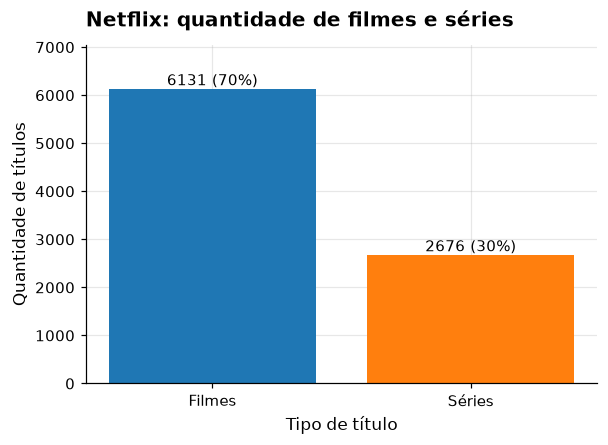

In [26]:
fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(['Filmes', 'Séries'], tipos.values, color=['#1f77b4', '#ff7f0e'])
ax.bar_label(barras, labels=[f'{v} ({v / tipos.sum():.0%})' for v in tipos.values])
ax.set_title('Netflix: quantidade de filmes e séries')
ax.set_xlabel('Tipo de título')
ax.set_ylabel('Quantidade de títulos')
ax.set_ylim(0, tipos.max() * 1.15)
plt.show()

O catálogo tem mais que o dobro de filmes em relação a séries.

### Gráfico 2 – Top 10 países

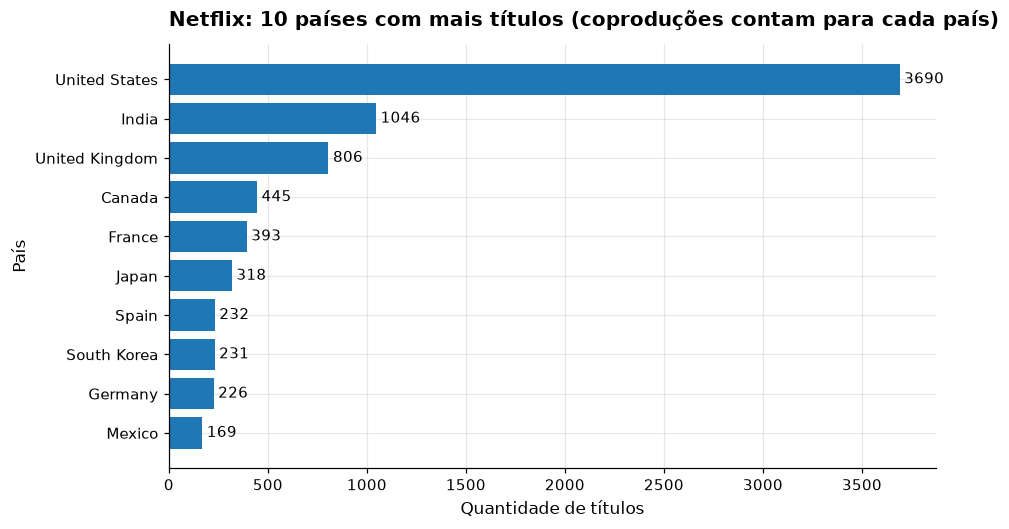

In [27]:
fig, ax = plt.subplots(figsize=(9, 5))
dados = top_paises.sort_values()
ax.barh(dados.index, dados.values, color='#1f77b4')
ax.bar_label(ax.containers[0], padding=3)
ax.set_title('Netflix: 10 países com mais títulos (coproduções contam para cada país)')
ax.set_xlabel('Quantidade de títulos')
ax.set_ylabel('País')
plt.show()

A liderança dos EUA é isolada; a Índia é o segundo maior produtor, bem à frente dos demais.

### Gráfico 3 – Títulos por ano de lançamento

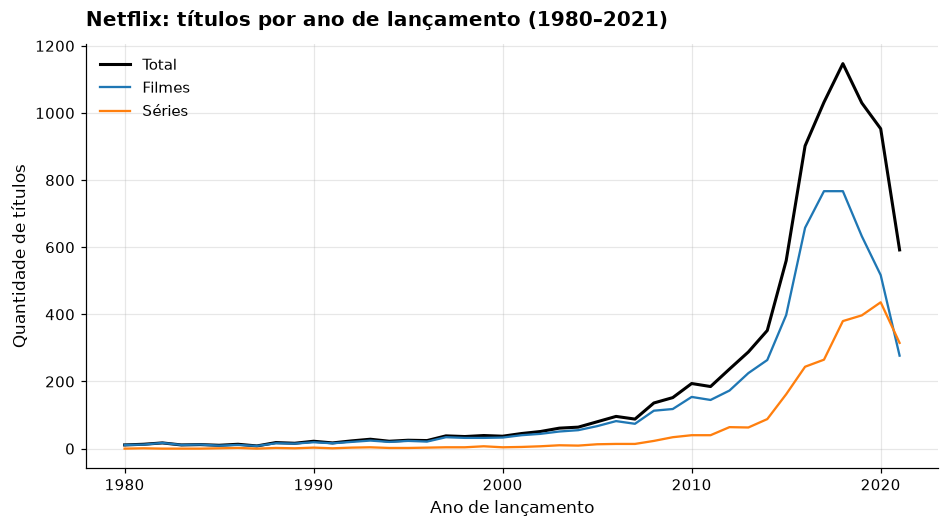

In [28]:
por_ano_tipo = netflix.groupby(['release_year', 'type']).size().unstack(fill_value=0).loc[1980:]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(por_ano.loc[1980:].index, por_ano.loc[1980:].values, label='Total', color='black', linewidth=2)
ax.plot(por_ano_tipo.index, por_ano_tipo['Movie'], label='Filmes', color='#1f77b4')
ax.plot(por_ano_tipo.index, por_ano_tipo['TV Show'], label='Séries', color='#ff7f0e')
ax.set_title('Netflix: títulos por ano de lançamento (1980–2021)')
ax.set_xlabel('Ano de lançamento')
ax.set_ylabel('Quantidade de títulos')
ax.legend()
plt.show()

Crescimento acelerado a partir de 2014, pico em 2018 e queda nos anos mais recentes (2021 incompleto).
As séries têm pico mais tardio (2020) do que os filmes (2017–2018) e, em 2021, chegam a superar os filmes (315 × 277). Anos anteriores a 1980 foram omitidos
por terem poucos títulos.

### Gráfico 4 (livre) – Títulos adicionados ao catálogo por ano

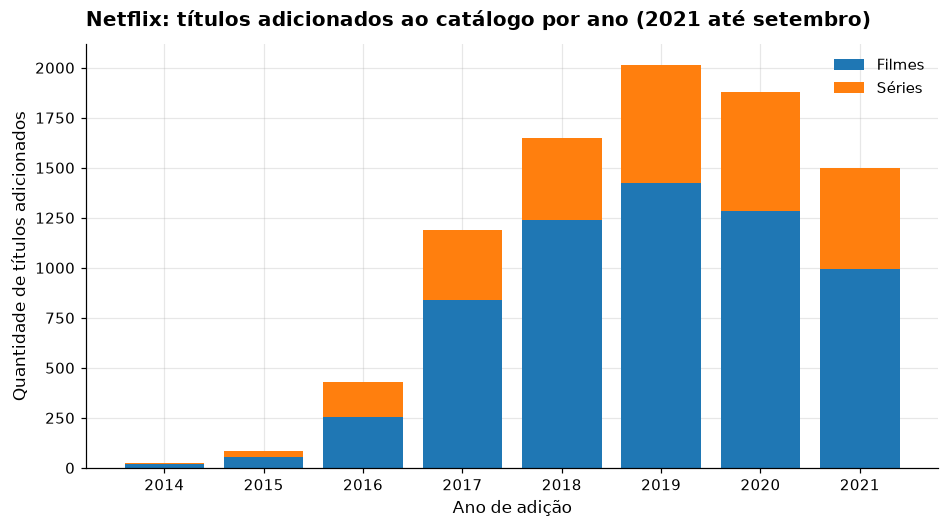

In [29]:
adicoes = netflix.groupby(['ano_adicao', 'type']).size().unstack(fill_value=0).loc[2014:]

fig, ax = plt.subplots(figsize=(10, 5))
anos = adicoes.index.astype(int).astype(str)
ax.bar(anos, adicoes['Movie'], label='Filmes', color='#1f77b4')
ax.bar(anos, adicoes['TV Show'], bottom=adicoes['Movie'], label='Séries', color='#ff7f0e')
ax.set_title('Netflix: títulos adicionados ao catálogo por ano (2021 até setembro)')
ax.set_xlabel('Ano de adição')
ax.set_ylabel('Quantidade de títulos adicionados')
ax.legend()
plt.show()

A expansão do catálogo acontece de 2016 a 2019 (pico de 2016 títulos adicionados em 2019). Antes de 2016
quase nada foi registrado, o que indica que a base retrata o catálogo de 2021, e não a história completa da
plataforma. A proporção de séries entre as adições cresce depois de 2018.

---
# 4. Students Performance – conhecendo e preparando os dados

In [30]:
alunos = pd.read_csv('data/StudentsPerformance.csv')
print('Linhas:', alunos.shape[0], '| Colunas:', alunos.shape[1])
alunos.head()

Linhas: 1000 | Colunas: 8


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [31]:
alunos.tail()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77
999,female,group D,some college,free/reduced,none,77,86,86


In [32]:
alunos.dtypes.rename('tipo').to_frame()

,tipo
gender,str
race/ethnicity,str
parental level of education,str
lunch,str
test preparation course,str
math score,int64
reading score,int64
writing score,int64


In [33]:
print('Linhas duplicadas:', alunos.duplicated().sum())
alunos.isna().sum().rename('ausentes').to_frame()

Linhas duplicadas: 0


,ausentes
gender,0
race/ethnicity,0
parental level of education,0
lunch,0
test preparation course,0
math score,0
reading score,0
writing score,0


In [34]:
# Categorias de cada coluna de texto e quantos alunos há em cada uma
categorias = pd.concat({col: alunos[col].value_counts() for col in alunos.select_dtypes(exclude='number').columns})
tabela(categorias.rename('alunos'), barras=['alunos'])

In [35]:
alunos.describe()

,math score,reading score,writing score
count,1000.00,1000.00,1000.00
mean,66.09,69.17,68.05
std,15.16,14.60,15.20
min,0.00,17.00,10.00
25%,57.00,59.00,57.75
50%,66.00,70.00,69.00
75%,77.00,79.00,79.00
max,100.00,100.00,100.00


### Preparação

In [36]:
# Nomes de colunas mais fáceis de usar
alunos = alunos.rename(columns={
    'gender': 'genero',
    'race/ethnicity': 'grupo',
    'parental level of education': 'escolaridade_pais',
    'lunch': 'almoco',
    'test preparation course': 'curso_prep',
    'math score': 'matematica',
    'reading score': 'leitura',
    'writing score': 'escrita',
})
notas = ['matematica', 'leitura', 'escrita']

# Ordem lógica para a escolaridade dos pais (da menor para a maior)
ordem_escolaridade = ['some high school', 'high school', 'some college',
                      "associate's degree", "bachelor's degree", "master's degree"]
alunos['escolaridade_pais'] = pd.Categorical(alunos['escolaridade_pais'],
                                             categories=ordem_escolaridade, ordered=True)
alunos.head()

,genero,grupo,escolaridade_pais,almoco,curso_prep,matematica,leitura,escrita
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


### Média e mediana das três notas

In [37]:
alunos[notas].agg(['mean', 'median']).round(2)

,matematica,leitura,escrita
mean,66.09,69.17,68.05
median,66.00,70.00,69.00


### O que o `describe()` mostra

1. **Base limpa:** 1000 alunos, nenhum valor ausente e nenhuma linha duplicada – não é necessário tratamento
   de dados, só renomear colunas.
2. **Leitura é a disciplina com notas mais altas** (média 69,2 e mediana 70), e **Matemática a mais baixa**
   (média 66,1 e mediana 66). Em todas as disciplinas média e mediana são próximas, sinal de distribuições
   aproximadamente simétricas.
3. **Dispersão parecida:** o desvio-padrão (`std`), que mede o quanto as notas costumam se afastar da média, fica
   em torno de 15 pontos nas três disciplinas. Em Matemática, ~70% dos alunos estão a até 1 desvio da média (entre
   ~51 e ~81). Os quartis dividem os alunos ordenados em 4 partes iguais: 25% tiram até o 1º quartil (`25%`) e 75%
   até o 3º (`75%`), então a metade central dos alunos está entre 57 e 77 pontos em Matemática (e entre
   ~58 e 79 em Leitura e Escrita).
4. **Valores extremos:** há pelo menos um aluno com **nota 0 em Matemática** (mínimo de leitura é 17 e de escrita 10),
   enquanto o máximo de 100 é atingido nas três. Os mínimos estão bem abaixo do 1º quartil – são casos raros,
   mas válidos (as notas estão dentro da escala 0–100), então foram mantidos.

---
# 5. Students Performance – análise de desempenho

### 5.1 Média de cada disciplina

In [38]:
medias = alunos[notas].mean().round(2)
medias.rename('média').to_frame()

,média
matematica,66.09
leitura,69.17
escrita,68.05


Leitura (69,17) > Escrita (68,05) > Matemática (66,09). A diferença entre a melhor e a pior é de ~3 pontos.

### 5.2 Mediana de cada disciplina

In [39]:
alunos[notas].median().rename('mediana').to_frame()

,mediana
matematica,66.00
leitura,70.00
escrita,69.00


As medianas (70, 69 e 66) seguem a mesma ordem das médias e ficam muito perto delas.

### 5.3 Disciplina com maior média

In [40]:
print('Maior média:', medias.idxmax(), '=', medias.max())

Maior média: leitura = 69.17


**Leitura** é a disciplina com maior média.

### 5.4 Coluna `media_geral`

In [41]:
alunos['media_geral'] = alunos[notas].mean(axis=1).round(2)
alunos[notas + ['media_geral']].head()

,matematica,leitura,escrita,media_geral
0,72,72,74,72.67
1,69,90,88,82.33
2,90,95,93,92.67
3,47,57,44,49.33
4,76,78,75,76.33


### 5.5 Top 10 estudantes por média geral

In [42]:
# keep='all' mantém os empatados na última posição (há 3 alunos com 97,67 disputando 2 vagas)
alunos.nlargest(10, 'media_geral', keep='all')

,genero,grupo,escolaridade_pais,almoco,curso_prep,matematica,leitura,escrita,media_geral
458,female,group E,bachelor's degree,standard,none,100,100,100,100.00
916,male,group E,bachelor's degree,standard,completed,100,100,100,100.00
962,female,group E,associate's degree,standard,none,100,100,100,100.00
114,female,group E,bachelor's degree,standard,completed,99,100,100,99.67
179,female,group D,some high school,standard,completed,97,100,100,99.00
712,female,group D,some college,standard,none,98,100,99,99.00
165,female,group C,bachelor's degree,standard,completed,96,100,100,98.67
625,male,group D,some college,standard,completed,100,97,99,98.67
149,male,group E,associate's degree,free/reduced,completed,100,100,93,97.67
685,female,group E,master's degree,standard,completed,94,99,100,97.67


Três alunos tiraram 100 nas três provas. A lista tem 11 linhas porque há empate triplo em 97,67 na 10ª posição.
Desses 11, 8 são mulheres, 9 têm almoço padrão e 6 são do grupo E – perfis que, como veremos abaixo, têm médias mais altas em geral.

### 5.6 Percentual de aprovados (média geral ≥ 70)

In [43]:
alunos['aprovado'] = alunos['media_geral'] >= 70
print(f"Aprovados: {alunos['aprovado'].sum()} de {len(alunos)} ({alunos['aprovado'].mean():.1%})")

Aprovados: 459 de 1000 (45.9%)


**45,9%** dos alunos atingem média geral ≥ 70: menos da metade seria aprovada por esse critério.

### 5.7 Média geral por gênero

In [44]:
alunos.groupby('genero')['media_geral'].mean().round(2).rename('média geral').to_frame()

,média geral
genero,
female,69.57
male,65.84


As mulheres têm média geral ~3,7 pontos maior (69,57 contra 65,84).

### 5.8 Média geral com e sem curso preparatório

In [45]:
tabela(alunos.groupby('curso_prep')['media_geral'].agg(['mean', 'count'])
       .rename(columns={'mean': 'média geral', 'count': 'alunos'}), barras=['média geral'])

,média geral,alunos
curso_prep,,
completed,72.67,358
none,65.04,642


Quem **completou o curso preparatório** tem média geral de 72,67, contra 65,04 de quem não fez:
~7,6 pontos a mais. Só 36% dos alunos fizeram o curso.

### 5.9 Média geral por escolaridade dos pais

In [46]:
tabela(alunos.groupby('escolaridade_pais', observed=True)['media_geral'].agg(['mean', 'count'])
       .rename(columns={'mean': 'média geral', 'count': 'alunos'}), barras=['média geral'])

,média geral,alunos
escolaridade_pais,,
some high school,65.11,179
high school,63.10,196
some college,68.48,226
associate's degree,69.57,222
bachelor's degree,71.92,118
master's degree,73.60,59


A média geral tende a subir com a escolaridade dos pais: de ~63–65 (ensino médio incompleto/completo)
até 73,6 (mestrado). A ordem não é perfeita – "some high school" fica acima de "high school" – mas a
diferença entre os extremos passa de 10 pontos.

### 5.10 Grupo (race/ethnicity) com maior média geral

In [47]:
por_grupo = alunos.groupby('grupo')['media_geral'].mean().round(2).sort_values(ascending=False)
print('Maior média:', por_grupo.idxmax())
tabela(por_grupo.rename('média geral'), barras=['média geral'])

Maior média: group E


,média geral
grupo,
group E,72.75
group D,69.18
group C,67.13
group B,65.47
group A,62.99


O **grupo E** tem a maior média geral (72,75), e há uma escada clara do grupo A (62,99) ao E. A base
não explica o que cada grupo representa, então não é possível interpretar essa diferença além da descrição.

---
# 6. Students Performance – visualização

### Gráfico 1 – Distribuição das notas de Matemática

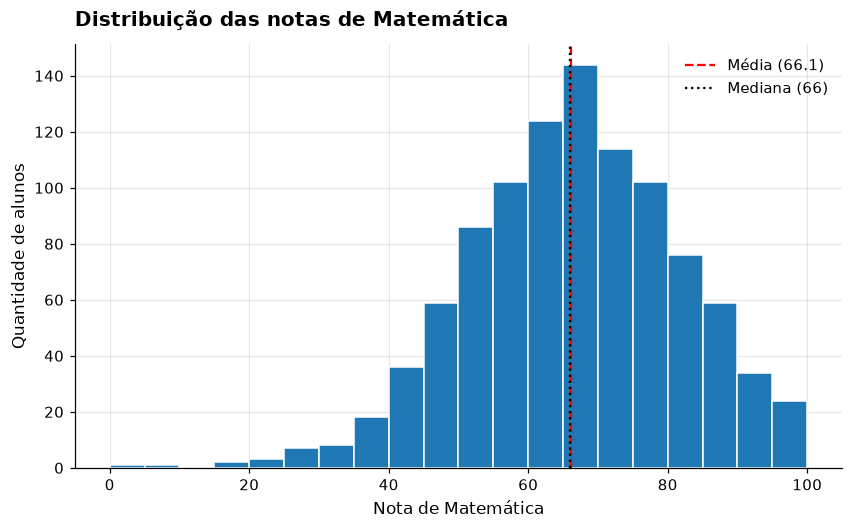

In [48]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(alunos['matematica'], bins=20, color='#1f77b4', edgecolor='white')
ax.axvline(alunos['matematica'].mean(), color='red', linestyle='--', label=f"Média ({alunos['matematica'].mean():.1f})")
ax.axvline(alunos['matematica'].median(), color='black', linestyle=':', label=f"Mediana ({alunos['matematica'].median():.0f})")
ax.set_title('Distribuição das notas de Matemática')
ax.set_xlabel('Nota de Matemática')
ax.set_ylabel('Quantidade de alunos')
ax.legend()
plt.show()

A distribuição tem formato de sino, concentrada entre 50 e 80, com média e mediana praticamente iguais.
A cauda esquerda é um pouco mais longa (poucos alunos abaixo de 30, incluindo a nota 0).

### Gráfico 2 – Média das três disciplinas

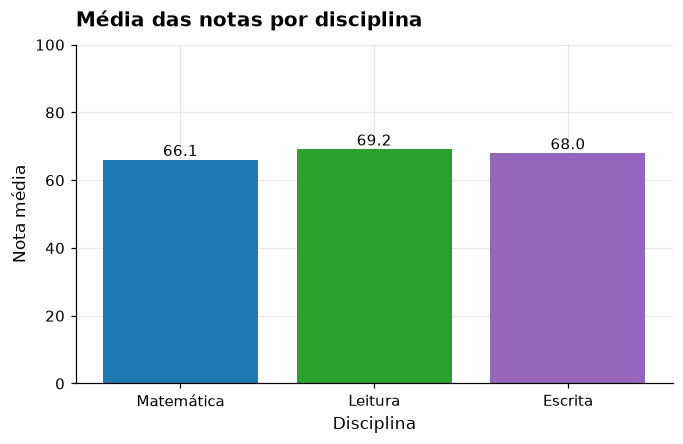

In [49]:
fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(['Matemática', 'Leitura', 'Escrita'], medias.values, color=['#1f77b4', '#2ca02c', '#9467bd'])
ax.bar_label(barras, fmt='%.1f')
ax.set_title('Média das notas por disciplina')
ax.set_xlabel('Disciplina')
ax.set_ylabel('Nota média')
ax.set_ylim(0, 100)
plt.show()

As três médias estão entre 66 e 70: a diferença existe, mas é pequena perto da escala 0–100. Matemática é a mais baixa.

### Gráfico 3 – Média geral por gênero

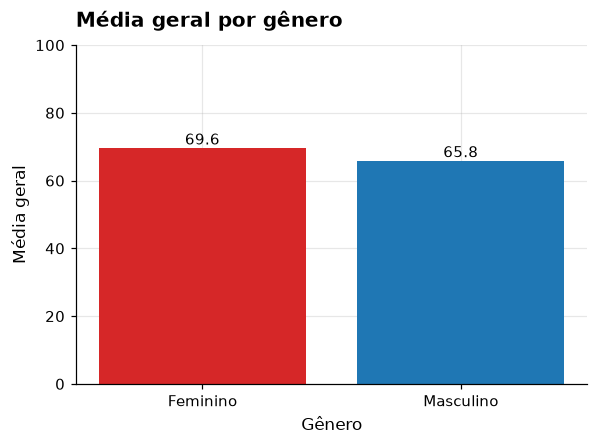

In [50]:
por_genero = alunos.groupby('genero')['media_geral'].mean()

fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(['Feminino', 'Masculino'], por_genero[['female', 'male']].values, color=['#d62728', '#1f77b4'])
ax.bar_label(barras, fmt='%.1f')
ax.set_title('Média geral por gênero')
ax.set_xlabel('Gênero')
ax.set_ylabel('Média geral')
ax.set_ylim(0, 100)
plt.show()

Mulheres têm média geral maior (69,6 contra 65,8). O eixo vai de 0 a 100 de propósito, para mostrar a diferença
na escala real das notas: 3,7 pontos é uma diferença pequena perto da escala, e um eixo cortado a exageraria. A seção 7 mostra que essa vantagem não vale para todas as disciplinas.

### Gráfico 4 – Com e sem curso preparatório

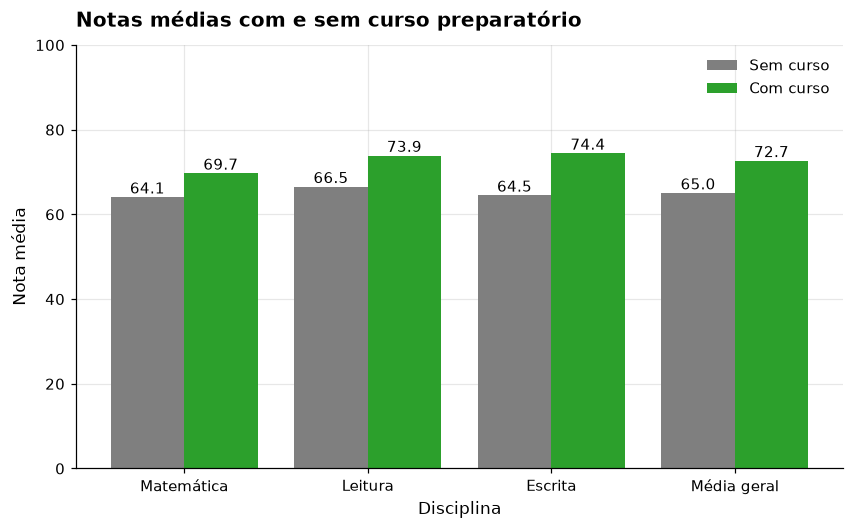

In [51]:
prep = alunos.groupby('curso_prep')[notas + ['media_geral']].mean().loc[['none', 'completed']]
rotulos = ['Matemática', 'Leitura', 'Escrita', 'Média geral']
x = range(len(rotulos))

fig, ax = plt.subplots(figsize=(9, 5))
b1 = ax.bar([i - 0.2 for i in x], prep.loc['none'], width=0.4, label='Sem curso', color='#7f7f7f')
b2 = ax.bar([i + 0.2 for i in x], prep.loc['completed'], width=0.4, label='Com curso', color='#2ca02c')
ax.bar_label(b1, fmt='%.1f')
ax.bar_label(b2, fmt='%.1f')
ax.set_xticks(list(x), rotulos)
ax.set_title('Notas médias com e sem curso preparatório')
ax.set_xlabel('Disciplina')
ax.set_ylabel('Nota média')
ax.set_ylim(0, 100)
ax.legend()
plt.show()

Quem fez o curso tem média maior em todas as disciplinas. A diferença é maior em **Escrita** (~10 pontos)
e menor em **Matemática** (~5,6 pontos). Por ser uma análise descritiva, não dá para afirmar que o curso
*causa* a melhora (os alunos que fazem o curso podem ser diferentes dos que não fazem).

### Gráfico 5 (livre) – Leitura × Escrita

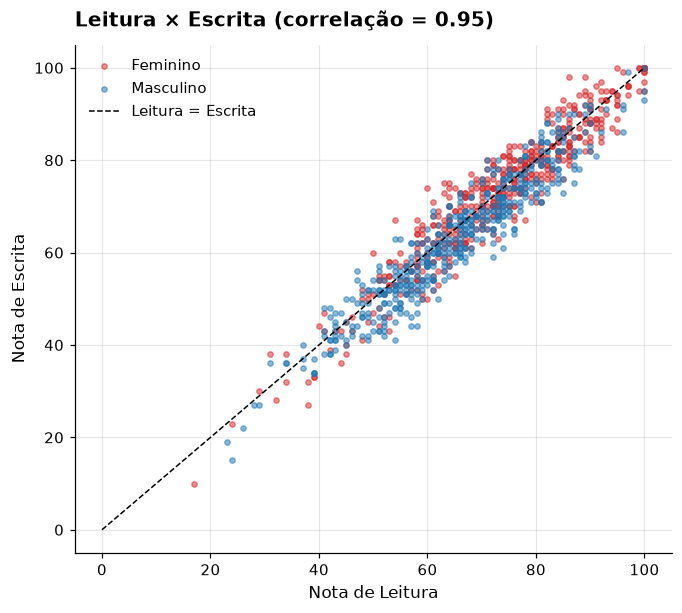

,matematica,leitura,escrita
matematica,1.000,0.818,0.803
leitura,0.818,1.000,0.955
escrita,0.803,0.955,1.000


In [52]:
fig, ax = plt.subplots(figsize=(7, 6))
for genero, cor, nome in [('female', '#d62728', 'Feminino'), ('male', '#1f77b4', 'Masculino')]:
    g = alunos[alunos['genero'] == genero]
    ax.scatter(g['leitura'], g['escrita'], s=12, alpha=0.5, color=cor, label=nome)
ax.plot([0, 100], [0, 100], color='black', linestyle='--', linewidth=1, label='Leitura = Escrita')
ax.set_title(f"Leitura × Escrita (correlação = {alunos['leitura'].corr(alunos['escrita']):.2f})")
ax.set_xlabel('Nota de Leitura')
ax.set_ylabel('Nota de Escrita')
ax.legend()
plt.show()

alunos[notas].corr().style.format(precision=3).background_gradient(cmap='Blues', vmin=0.7, vmax=1).set_table_attributes('class="dataframe"')

Leitura e escrita andam quase juntas (correlação de 0,95): quem lê bem quase sempre escreve bem. A correlação
vai de −1 a 1; perto de 1 indica que as duas notas sobem juntas quase em linha reta – mas não diz que uma causa a outra. A correlação
com Matemática também é alta (~0,8), mas menor. Os pontos azuis (homens) ficam mais abaixo da diagonal,
ou seja, eles costumam ter escrita um pouco menor que a leitura.

---
# 7. Investigação livre

## Netflix – Pergunta 1: a Netflix está adicionando títulos cada vez mais antigos?

Pergunta: quanto tempo passa entre o **lançamento** de um título e a sua **adição** ao catálogo, e
isso mudou ao longo dos anos? Isso mostra se a plataforma está apostando em novidades ou em acervo.

Tratamento: `defasagem = ano_adicao - release_year`, apenas para anos de adição 2015–2021 (antes disso há
poucos registros). Defasagens negativas (adicionado antes do lançamento) são erros de cadastro e foram removidas.

In [53]:
recentes = netflix[netflix['ano_adicao'].between(2015, 2021)].copy()
recentes['defasagem'] = recentes['ano_adicao'] - recentes['release_year']
print('Defasagens negativas removidas:', (recentes['defasagem'] < 0).sum())
recentes = recentes[recentes['defasagem'] >= 0]

defasagem = recentes.groupby(['ano_adicao', 'type'])['defasagem'].mean().unstack().round(2)
novidades = recentes.groupby('ano_adicao')['defasagem'].apply(lambda d: (d <= 1).mean() * 100).round(1)
defasagem['% adicionados até 1 ano após lançar'] = novidades
defasagem

Defasagens negativas removidas: 13


type,Movie,TV Show,% adicionados até 1 ano após lançar
ano_adicao,,,
2015,0.41,3.35,81.70
2016,1.99,4.37,65.30
2017,4.16,3.41,59.70
2018,4.79,2.14,54.70
2019,6.66,1.96,51.50
2020,6.03,1.78,55.40
2021,7.70,1.92,50.80


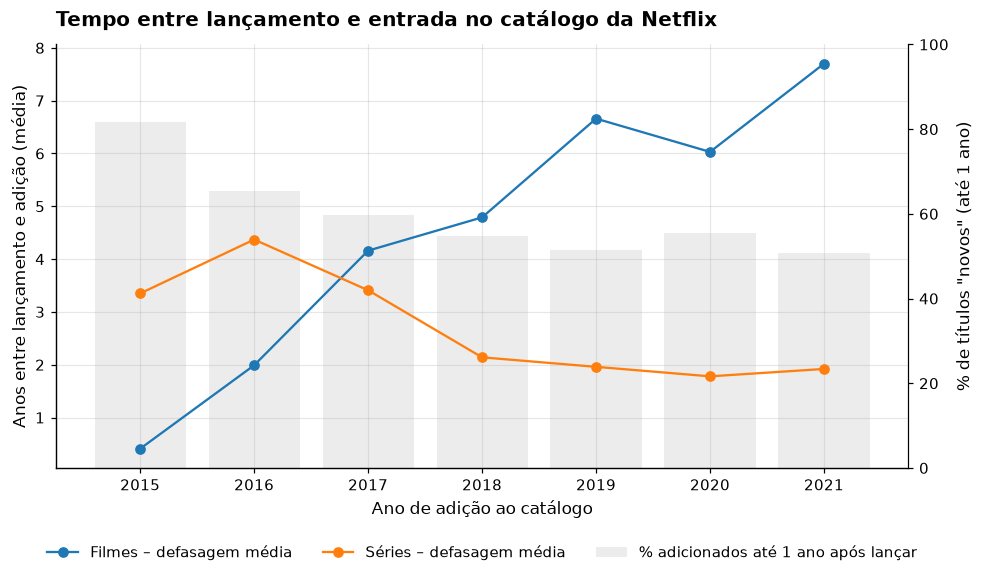

In [54]:
fig, ax1 = plt.subplots(figsize=(10, 5))
anos = defasagem.index.astype(int)
ax1.plot(anos, defasagem['Movie'], marker='o', label='Filmes – defasagem média', color='#1f77b4')
ax1.plot(anos, defasagem['TV Show'], marker='o', label='Séries – defasagem média', color='#ff7f0e')
ax1.set_xlabel('Ano de adição ao catálogo')
ax1.set_ylabel('Anos entre lançamento e adição (média)')

ax2 = ax1.twinx()
ax2.bar(anos, defasagem['% adicionados até 1 ano após lançar'], alpha=0.15, color='gray',
        label='% adicionados até 1 ano após lançar')
ax2.set_ylabel('% de títulos "novos" (até 1 ano)')
ax2.set_ylim(0, 100)
ax2.grid(False)
ax2.spines['right'].set_visible(True)

linhas1, rot1 = ax1.get_legend_handles_labels()
linhas2, rot2 = ax2.get_legend_handles_labels()
ax1.legend(linhas1 + linhas2, rot1 + rot2, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3)
ax1.set_zorder(ax2.get_zorder() + 1)
ax1.patch.set_visible(False)
ax1.set_title('Tempo entre lançamento e entrada no catálogo da Netflix')
plt.show()

**Conclusão:** em 2015, 82% dos títulos adicionados tinham sido lançados no mesmo ano ou no anterior; em
2021 esse percentual caiu para ~51%. A defasagem média dos **filmes** sobe de 0,4 para 7,7 anos: a Netflix
passou a incluir cada vez mais filmes de acervo. Já nas **séries** a defasagem é baixa e até diminui depois de 2016 – mas isso
pode ser efeito da base: para séries, `release_year` parece indicar o ano da temporada mais recente, e não
da estreia, o que "rejuvenesce" artificialmente as séries.

## Netflix – Pergunta 2: os filmes estão ficando mais curtos?

Pergunta: a duração dos filmes no catálogo muda conforme a década de lançamento?

Tratamento: apenas filmes (`duracao_num` em minutos), agrupados por década de lançamento. Usamos a **mediana**
porque há filmes muito curtos (curtas, especiais) e muito longos que distorcem a média. A década de 1940 tem
só 13 filmes (documentários curtos de guerra) e 1950 só 11, então são lidas com cautela.

In [55]:
dur_decada = (filmes.groupby('decada')['duracao_num']
              .agg(mediana='median', media='mean', q1=lambda d: d.quantile(0.25),
                   q3=lambda d: d.quantile(0.75), filmes='count')
              .round(1))
dur_decada

,mediana,media,q1,q3,filmes
decada,,,,,
1940,52.00,51.40,40.00,61.00,13
1950,108.00,107.10,97.50,115.50,11
1960,152.00,147.60,121.50,169.50,23
1970,113.50,119.20,96.20,135.80,66
1980,105.50,116.20,93.00,134.00,122
1990,108.00,113.80,94.00,130.00,241
2000,108.00,112.10,95.00,128.00,677
2010,97.00,96.90,85.00,111.00,4184
2020,97.00,93.60,83.00,111.00,794


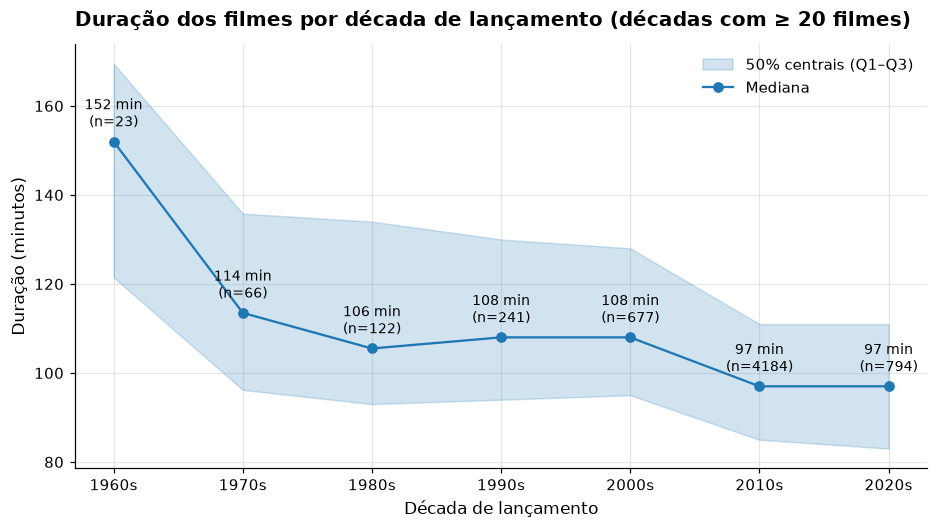

In [56]:
fig, ax = plt.subplots(figsize=(10, 5))
d = dur_decada[dur_decada['filmes'] >= 20]
rot = [f'{int(dec)}s' for dec in d.index]
ax.fill_between(rot, d['q1'], d['q3'], alpha=0.2, color='#1f77b4', label='50% centrais (Q1–Q3)')
ax.plot(rot, d['mediana'], marker='o', color='#1f77b4', label='Mediana')
for r, v, n in zip(rot, d['mediana'], d['filmes']):
    ax.annotate(f'{v:.0f} min\n(n={n})', (r, v), textcoords='offset points', xytext=(0, 10), ha='center', fontsize=9)
ax.set_title('Duração dos filmes por década de lançamento (décadas com ≥ 20 filmes)')
ax.set_xlabel('Década de lançamento')
ax.set_ylabel('Duração (minutos)')
ax.legend()
plt.show()

**Conclusão:** os filmes recentes do catálogo são mais curtos. A mediana fica entre ~106 e ~114 minutos dos anos
1970 aos 2000 e cai para **97 minutos** nas décadas de 2010 e 2020; a faixa central (Q1–Q3) também desce. A
década de 1960 é a mais longa (mediana 152 min), mas tem poucos filmes – provavelmente épicos e clássicos
selecionados. Parte da queda recente pode vir do tipo de conteúdo que a Netflix inclui (especiais de stand-up,
documentários e animações curtas), e não só de mudança no cinema em geral.

## Students – Pergunta 1: a vantagem das mulheres vale para todas as disciplinas?

Pergunta: na seção 5 as mulheres têm média geral maior. Essa vantagem é igual em todas as disciplinas,
ou muda de sinal conforme a matéria? Tratamento: média de cada disciplina por gênero e a diferença
(feminino − masculino); também comparamos o percentual de alunos com nota ≥ 70 em cada disciplina.

In [57]:
por_genero_disc = alunos.groupby('genero')[notas].mean().T
por_genero_disc['diferenca (F - M)'] = por_genero_disc['female'] - por_genero_disc['male']
pct70 = alunos.groupby('genero')[notas].agg(lambda s: (s >= 70).mean() * 100).T.add_prefix('% ≥70 ')
pd.concat([por_genero_disc, pct70], axis=1).round(2)

genero,female,male,diferenca (F - M),% ≥70 female,% ≥70 male
matematica,63.63,68.73,-5.10,34.36,47.93
leitura,72.61,65.47,7.14,61.39,40.46
escrita,72.47,63.31,9.16,62.74,34.02


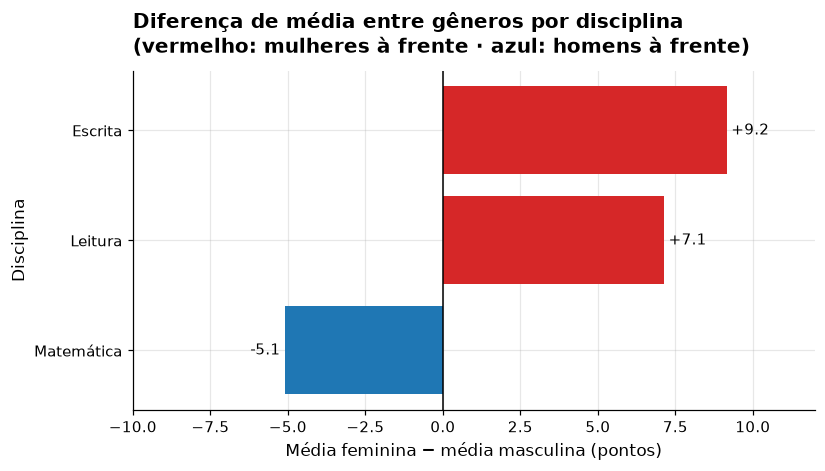

In [58]:
fig, ax = plt.subplots(figsize=(8, 4))
dif = por_genero_disc['diferenca (F - M)']
cores = ['#1f77b4' if v < 0 else '#d62728' for v in dif]
barras = ax.barh(['Matemática', 'Leitura', 'Escrita'], dif.values, color=cores)
ax.bar_label(barras, fmt='%+.1f', padding=3)
ax.axvline(0, color='black', linewidth=1)
ax.set_title('Diferença de média entre gêneros por disciplina\n(vermelho: mulheres à frente · azul: homens à frente)')
ax.set_xlabel('Média feminina − média masculina (pontos)')
ax.set_ylabel('Disciplina')
ax.set_xlim(-10, 12)
plt.show()

**Conclusão:** a vantagem **muda de sinal**. Os homens têm média ~5 pontos maior em **Matemática**, enquanto as
mulheres ficam ~7 pontos à frente em **Leitura** e ~9 pontos em **Escrita**. A média geral feminina é maior
porque duas das três disciplinas favorecem as mulheres – olhar só a média geral esconderia a inversão em Matemática.

## Students – Pergunta 2: curso preparatório compensa a desvantagem do almoço subsidiado?

Pergunta: o tipo de almoço (`free/reduced` = subsidiado, um indicador indireto de renda familiar) e o curso
preparatório estão ligados à média geral. Como os dois se combinam? Um aluno com almoço subsidiado que fez o
curso alcança quem tem almoço padrão sem curso?

Tratamento: tabela cruzada (`pivot_table`) de média geral e % de aprovados (média ≥ 70) para as 4 combinações.

In [59]:
combo = alunos.pivot_table(index='almoco', columns='curso_prep', values='media_geral', aggfunc='mean').round(2)
aprov = alunos.pivot_table(index='almoco', columns='curso_prep', values='aprovado', aggfunc='mean').mul(100).round(1)
qtd = alunos.pivot_table(index='almoco', columns='curso_prep', values='media_geral', aggfunc='count')
pd.concat({'média geral': combo, '% aprovados': aprov, 'alunos': qtd}, axis=1)

média geral       % aprovados          alunos     
curso_prep     completed  none   completed  none completed none
almoco                                                         
free/reduced       67.76 58.95       47.30 21.40       131  224
standard           75.51 68.30       68.70 46.20       227  418

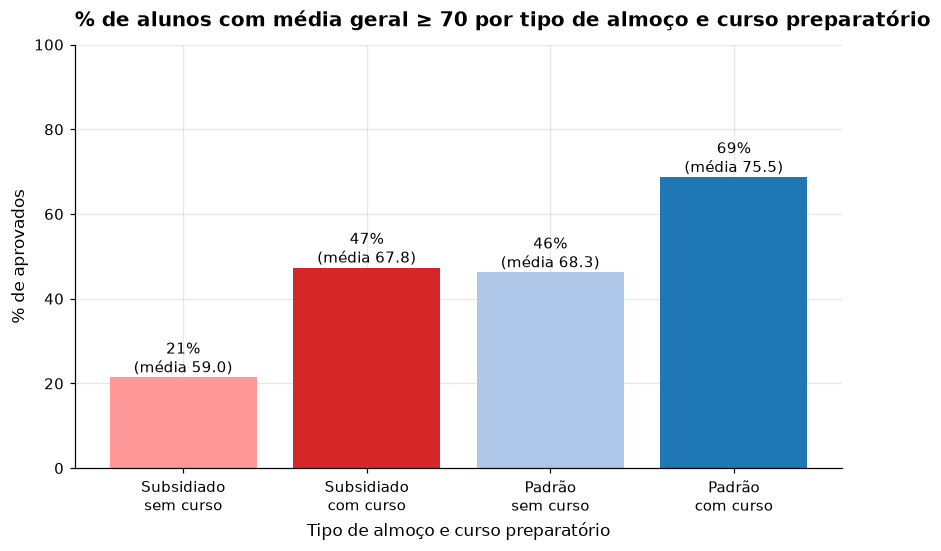

In [60]:
grupos = [('free/reduced', 'none'), ('free/reduced', 'completed'), ('standard', 'none'), ('standard', 'completed')]
rotulos = ['Subsidiado\nsem curso', 'Subsidiado\ncom curso', 'Padrão\nsem curso', 'Padrão\ncom curso']
valores = [aprov.loc[a, c] for a, c in grupos]
cores = ['#ff9896', '#d62728', '#aec7e8', '#1f77b4']

fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.bar(rotulos, valores, color=cores)
ax.bar_label(barras, labels=[f'{v:.0f}%\n(média {combo.loc[a, c]:.1f})' for v, (a, c) in zip(valores, grupos)])
ax.set_title('% de alunos com média geral ≥ 70 por tipo de almoço e curso preparatório')
ax.set_xlabel('Tipo de almoço e curso preparatório')
ax.set_ylabel('% de aprovados')
ax.set_ylim(0, 100)
plt.show()

**Conclusão:** os dois fatores somam. A distância entre o pior grupo (subsidiado sem curso, média 58,9) e o melhor
(padrão com curso, 75,5) é de ~16,5 pontos, e o percentual de aprovados mais que triplica (21% → 69%). O resultado mais interessante
é o cruzamento: **alunos com almoço subsidiado que fizeram o curso** (média 67,8) ficam praticamente no mesmo
nível dos **alunos com almoço padrão sem curso** (68,3). Descritivamente, o curso está associado a uma diferença
do mesmo tamanho que a associada ao tipo de almoço – sem que isso prove relação de causa.

---
# 8. Conclusões

### Principais descobertas – Netflix
1. **Catálogo de filmes, americano e recente:** 70% são filmes; os EUA aparecem em 3690 títulos (3,5× a Índia, 2ª);
   67% dos títulos foram lançados na década de 2010.
2. **Conteúdo adulto predomina:** TV-MA e TV-14 somam ~61% dos títulos.
3. **Acervo cada vez mais antigo nas adições:** o percentual de títulos adicionados até 1 ano após o lançamento
   caiu de 82% (2015) para ~51% (2021), puxado pelos filmes.
4. **Filmes recentes são mais curtos:** mediana de 97 min nas décadas de 2010/2020, contra ~106–114 min
   de 1970 a 2000; a duração mais comum é 90 minutos.
5. **"International" é um rótulo de origem, não de gênero:** está em ~80% dos títulos sem os EUA e em só ~6,5%
   dos títulos com os EUA; entre os gêneros propriamente ditos, Dramas e Comedies lideram.

### Principais descobertas – Estudantes
1. **Menos da metade aprovaria:** só 45,9% têm média geral ≥ 70; Matemática é a disciplina mais difícil (média 66,1).
2. **Gênero inverte conforme a disciplina:** homens ~5 pontos à frente em Matemática; mulheres ~7 em Leitura e ~9 em Escrita.
3. **Curso preparatório e almoço pesam igual:** quem fez o curso tem ~7,6 pontos a mais; alunos de almoço subsidiado
   com curso alcançam os de almoço padrão sem curso.
4. **Notas muito correlacionadas:** leitura e escrita têm correlação de 0,95 – quem vai bem numa vai bem na outra.
5. **Escolaridade dos pais e grupo** também se associam à média (até ~10 pontos entre extremos).

### Características das bases que dificultaram a análise
- **Netflix:** listas dentro de células (`country`, `director`, `listed_in`) exigindo `split` + `explode`; muitos ausentes em
  `director` (30%); `duration` com unidades diferentes para filmes e séries; valores trocados entre `rating` e `duration`;
  datas como texto; `release_year` de séries que parece indicar a temporada mais recente.
- **Students:** praticamente nenhum problema de qualidade, mas variáveis pouco informativas (`race/ethnicity` só tem
  "group A–E", sem explicação) e escolaridade dos pais sem ordem natural no arquivo.

### Qual base permitiu análises mais interessantes?
A **Netflix**, por ter mais variáveis e dimensões (tempo de lançamento, tempo de adição, países, gêneros, duração): foi
possível investigar tendências ao longo do tempo, algo que a base de estudantes não permite. Em contrapartida, a base
de **estudantes**, limpa e com notas numéricas, permitiu comparações diretas entre grupos e revelou um resultado
contra-intuitivo (a inversão de gênero entre disciplinas).

### Limitações
- As análises são **descritivas**: diferenças entre grupos não provam causa (ex.: efeito do curso preparatório).
- A Netflix é uma **fotografia do catálogo em setembro de 2021**: títulos removidos antes disso não aparecem, 2021 está
  incompleto e há poucos registros de adição antes de 2016.
- Rankings de países e diretores ignoram os títulos sem essa informação, e coproduções contam para todos os países.
- A base de estudantes tem só 1000 alunos, de origem não documentada (é uma base fictícia/educacional no Kaggle), então
  os resultados não devem ser generalizados para populações reais.